# 08 · Construir un GPT: un modelo generalista a partir de predecir el siguiente token

**GPT** = **G**enerative **P**re-trained **T**ransformer (transformer generativo preentrenado). Es la mitad decodificadora del transformer del notebook 07, entrenada con un objetivo engañosamente simple:

> dado el texto hasta ahora, predice el siguiente token.

Haz eso con suficiente texto variado y el modelo tiene que aprender gramática, hechos, aritmética, traducción y patrones de razonamiento, porque todo eso ayuda a predecir lo que viene después. La *misma* red realiza entonces una tarea elegida simplemente por cómo está escrita la instrucción (el prompt). Eso es lo que la convierte en un modelo **generalista**.

En este notebook construimos un GPT desde cero y lo preentrenamos con un pequeño corpus multitarea (sumas, inversión de cadenas, ordenación, traducción de inglés a español y capitales del mundo), todo escrito como texto plano. Un modelo, una pérdida, cinco habilidades.

El corpus de entrenamiento está **en inglés** (las instrucciones de las tareas y los nombres de países, por ejemplo `capital peru=lima`), así que las salidas del modelo que verás más abajo también lo están; el notebook explica cada una.

**Contenido**
1. GPT en contexto
2. Tokenización: caracteres, palabras y Byte-Pair Encoding (BPE)
3. Un corpus de preentrenamiento multitarea
4. La arquitectura GPT
5. Antes de entrenar: un modelo que no sabe nada
6. Preentrenamiento, y cómo surgen las habilidades
7. Usar el generalista: instrucciones para distintas tareas (y alucinaciones)
8. Muestreo: voraz, temperatura, top-k, top-p
9. Dentro del modelo: la atención mientras suma
10. Generación rápida con una caché KV
11. Ajuste fino: por qué importa el preentrenamiento
12. De un modelo base a ChatGPT, y las leyes de escala
13. Ejercicios

⏱ Tiempo de ejecución: unos 15 minutos en la CPU de un equipo personal, casi todo en la sección 6.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import math, random, time
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

random.seed(0); np.random.seed(0); torch.manual_seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))

## 1. GPT en contexto

| Modelo | Año | Parámetros | Tokens de entrenamiento | Qué cambió |
|---|---|---|---|---|
| GPT-1 | 2018 | 117 M | ~1.000 M | preentrenar con libros y después ajustar para cada tarea |
| GPT-2 | 2019 | 1.500 M | ~10.000 M (WebText) | tareas sin ejemplos (zero-shot) solo con la instrucción |
| GPT-3 | 2020 | 175.000 M | ~300.000 M | **aprendizaje en contexto**: mostrar unos pocos ejemplos en la instrucción |
| InstructGPT / ChatGPT | 2022 | (GPT-3.5) | + retroalimentación humana | el ajuste por instrucciones + RLHF convierten un modelo base en un asistente |
| GPT-4 y modelos de frontera posteriores | 2023+ | no publicado | no publicado | multimodales, mucho más grandes, mezcla de expertos, contexto largo, uso de herramientas |

La arquitectura apenas cambió a lo largo de esta tabla. Lo que creció fue la **escala** (parámetros, datos, cálculo) y el **postentrenamiento** que convierte un predictor de texto en un asistente útil. El modelo que construimos tiene la misma estructura que GPT-2, solo que unas 2.000 veces más pequeño.

## 2. Tokenización

Un modelo lee enteros, no texto. Hay tres opciones para hacer la correspondencia:

| Unidad | Vocabulario | Longitud de la secuencia | Problema |
|---|---|---|---|
| Caracteres | diminuto (~100) | larga | el modelo debe aprender ortografía; las secuencias se alargan |
| Palabras | enorme (más de 100.000) | corta | palabras desconocidas, nada compartido entre "run" y "running" |
| **Subpalabras (BPE)** | elegido (GPT-2: 50.257) | media | el compromiso estándar |

**Byte-Pair Encoding** empieza con los caracteres y **fusiona** repetidamente **el par adyacente más frecuente** en un token nuevo. Las palabras frecuentes se convierten en un solo token y las raras se dividen en piezas reutilizables. Abajo está el algoritmo completo.

In [2]:
sample_text = (
    "the model learns to predict the next token. the next token depends on the tokens before it. "
    "a token can be a word, a part of a word, or a single character. learning to predict the next "
    "word teaches the model grammar, facts and reasoning, because all of them help prediction. "
    "transformers use attention to let every token look at the tokens that came before it."
)

def bpe_train(text, n_merges):
    seq = list(text)                         # se empieza por los caracteres
    merges = []
    for _ in range(n_merges):
        pairs = Counter(zip(seq, seq[1:]))
        (a, b), count = pairs.most_common(1)[0]
        if count < 2:
            break
        merges.append((a, b))
        new, i = [], 0
        while i < len(seq):                  # se sustituye cada aparición del par
            if i < len(seq) - 1 and seq[i] == a and seq[i + 1] == b:
                new.append(a + b); i += 2
            else:
                new.append(seq[i]); i += 1
        seq = new
    return merges, seq

def bpe_encode(text, merges):
    seq = list(text)
    for a, b in merges:                      # se aplican las fusiones en el orden en que se aprendieron
        new, i = [], 0
        while i < len(seq):
            if i < len(seq) - 1 and seq[i] == a and seq[i + 1] == b:
                new.append(a + b); i += 2
            else:
                new.append(seq[i]); i += 1
        seq = new
    return seq

merges, tokens = bpe_train(sample_text, 40)
print("primeras 15 fusiones:", [a + b for a, b in merges[:15]])
print(f"\n{len(sample_text)} caracteres -> {len(tokens)} tokens tras {len(merges)} fusiones "
      f"({len(sample_text) / len(tokens):.1f} caracteres por token)\n")
print("codificación de una frase nueva:", bpe_encode("the next word predicts the model", merges))

primeras 15 fusiones: [' t', 'e ', ' to', ' th', 'en', 'or', ' tok', ' token', ' a', 'ar', 'ct', ' l', ' p', 're', ' the ']

360 caracteres -> 178 tokens tras 40 fusiones (2.0 caracteres por token)

codificación de una frase nueva: ['t', 'h', 'e ', 'n', 'e', 'x', 't ', 'word', ' predict', 's', ' the ', 'mode', 'l']


Fíjate en que palabras comunes como *the* y *token* se convirtieron en un solo token, mientras que las palabras nuevas se construyen con piezas. Los tokenizadores reales aplican BPE sobre **bytes** en terabytes de texto.

Para nuestro pequeño modelo usamos **caracteres**: un vocabulario de unos 40 símbolos mantiene el modelo pequeño y le permite ver exactamente cómo funcionan la suma y la inversión dígito a dígito. Todo lo demás en este notebook es idéntico con un vocabulario BPE.

## 3. Un corpus de preentrenamiento multitarea

Los GPT reales se preentrenan con páginas web, libros, código y artículos, que contienen implícitamente incontables "tareas". Lo imitamos con cinco tipos de tarea, mezclados en un único flujo de texto plano, un ejemplo por línea:

| Tarea | Línea de ejemplo | Qué requiere |
|---|---|---|
| `add` | `add 23+58=81` | un algoritmo (llevarse dígitos) |
| `rev` | `rev kqzpa=apzqk` | un algoritmo (copiar al revés) |
| `sort` | `sort 5 2 9 2=2 2 5 9` | un algoritmo (ordenar) |
| `es` | `es she wants the red car=ella quiere el coche rojo` | lenguaje: vocabulario, conjugación, concordancia, orden de las palabras |
| `capital` | `capital peru=lima` | **hechos** memorizados |

Para probar la **generalización** real, reservamos 500 sumas y 120 frases que el modelo nunca ve durante el entrenamiento, y la inversión usa cada vez cadenas aleatorias nuevas. Las capitales solo pueden memorizarse, así que con ellas probamos el recuerdo de hechos de entrenamiento.

In [3]:
COUNTRIES = {"france": "paris", "spain": "madrid", "italy": "rome", "germany": "berlin", "portugal": "lisbon",
             "japan": "tokyo", "egypt": "cairo", "peru": "lima", "chile": "santiago", "kenya": "nairobi",
             "canada": "ottawa", "norway": "oslo", "greece": "athens", "poland": "warsaw", "cuba": "havana",
             "india": "new delhi", "china": "beijing", "russia": "moscow", "mexico": "mexico city", "ireland": "dublin",
             "austria": "vienna", "sweden": "stockholm", "finland": "helsinki", "turkey": "ankara", "brazil": "brasilia",
             "argentina": "buenos aires", "colombia": "bogota", "costa rica": "san jose", "morocco": "rabat", "australia": "canberra"}

SUBJ = [("i", "yo", 0), ("you", "tú", 1), ("he", "él", 2), ("she", "ella", 2), ("we", "nosotros", 3), ("they", "ellos", 4)]
VERB = {"eat": ("eats", ["como", "comes", "come", "comemos", "comen"]),
        "see": ("sees", ["veo", "ves", "ve", "vemos", "ven"]),
        "want": ("wants", ["quiero", "quieres", "quiere", "queremos", "quieren"]),
        "buy": ("buys", ["compro", "compras", "compra", "compramos", "compran"]),
        "have": ("has", ["tengo", "tienes", "tiene", "tenemos", "tienen"])}
NOUN = [("apple", "manzana", "f"), ("book", "libro", "m"), ("car", "coche", "m"), ("house", "casa", "f"),
        ("dog", "perro", "m"), ("table", "mesa", "f"), ("cat", "gato", "m"), ("shirt", "camisa", "f")]
ADJ = [("red", "rojo", "roja"), ("new", "nuevo", "nueva"), ("old", "viejo", "vieja"), ("white", "blanco", "blanca"), (None, None, None)]

def translation_pairs():
    out = []
    for en_s, es_s, p in SUBJ:
        for v, (v3, conj) in VERB.items():
            for en_n, es_n, g in NOUN:
                for en_a, am, af in ADJ:
                    en = f"{en_s} {v3 if en_s in ('he', 'she') else v} the {en_a + ' ' if en_a else ''}{en_n}"
                    es = f"{es_s} {conj[p]} {'el' if g == 'm' else 'la'} {es_n}" + (f" {am if g == 'm' else af}" if en_a else "")
                    out.append((en, es))
    return out

ALL_TR = translation_pairs()
random.shuffle(ALL_TR)
TR_TEST, TR_TRAIN = ALL_TR[:120], ALL_TR[120:]
ADD_ALL = [(a, b) for a in range(100) for b in range(100)]
random.shuffle(ADD_ALL)
ADD_TEST, ADD_TRAIN = ADD_ALL[:500], ADD_ALL[500:]

def rand_word():
    return "".join(random.choice("abcdefghijklmnopqrstuvwxyz") for _ in range(random.randint(3, 6)))

def example(task, split="train"):
    # devuelve (instrucción, respuesta); una línea de entrenamiento es instrucción + respuesta
    if task == "add":
        a, b = random.choice(ADD_TRAIN if split == "train" else ADD_TEST)
        return f"add {a}+{b}=", f"{a + b}"
    if task == "rev":
        w = rand_word()
        return f"rev {w}=", w[::-1]
    if task == "sort":
        ds = [random.randint(0, 9) for _ in range(random.randint(3, 6))]
        return f"sort {' '.join(map(str, ds))}=", " ".join(map(str, sorted(ds)))
    if task == "es":
        en, es = random.choice(TR_TRAIN if split == "train" else TR_TEST)
        return f"es {en}=", es
    if task == "capital":
        c = random.choice(list(COUNTRIES))
        return f"capital {c}=", COUNTRIES[c]

TASKS = ["add", "rev", "sort", "es", "capital"]
WEIGHTS = [5, 1, 2, 1, 1]          # la aritmética es la habilidad más difícil, así que recibe más datos
corpus = "\n".join("".join(example(random.choices(TASKS, WEIGHTS)[0])) for _ in range(60000)) + "\n"

print(f"corpus: {len(corpus):,} caracteres, {corpus.count(chr(10)):,} líneas\n")
print(corpus[:400])

corpus: 1,194,459 caracteres, 60,000 líneas

es you have the white table=tú tienes la mesa blanca
add 10+13=23
rev nmnhrz=zrhnmn
add 43+55=98
capital canada=ottawa
add 48+20=68
add 6+63=69
add 45+78=123
add 2+66=68
add 50+33=83
rev jkpct=tcpkj
rev twd=dwt
add 79+2=81
add 18+75=93
add 49+40=89
add 41+51=92
sort 3 4 8=3 4 8
add 90+5=95
rev hghj=jhgh
sort 3 7 1=1 3 7
add 15+66=81
sort 6 5 7 2 9 9=2 5 6 7 9 9
add 34+25=59
capital australia=canbe


In [4]:
chars = sorted(set(corpus) | set("".join(e for pair in ALL_TR for e in pair)))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)
data = torch.tensor(encode(corpus), dtype=torch.long)

print(f"vocabulario ({len(chars)} tokens): {''.join(chars)!r}")
print("encode('add 2+2=4') ->", encode("add 2+2=4"))

vocabulario (42 tokens): '\n +0123456789=abcdefghijklmnopqrstuvwxyzéú'
encode('add 2+2=4') -> [14, 17, 17, 1, 5, 2, 5, 13, 7]


**Los ejemplos de entrenamiento son simplemente ventanas de texto.** Cortamos fragmentos aleatorios de `BLOCK = 64` caracteres del corpus. La entrada es el fragmento y el objetivo es el mismo fragmento desplazado un carácter. Así, cada posición de cada fragmento es un ejemplo de entrenamiento: *"dado `add 23+5`, predice `8`"*. Un fragmento de 64 caracteres da 64 predicciones a la vez, gracias a la máscara causal.

In [5]:
BLOCK = 64

def get_batch(B, source=None):
    source = data if source is None else source
    ix = torch.randint(len(source) - BLOCK - 1, (B,))
    x = torch.stack([source[i:i + BLOCK] for i in ix])
    y = torch.stack([source[i + 1:i + BLOCK + 1] for i in ix])
    return x, y

x, y = get_batch(1)
for t in range(12):
    print(f"contexto {decode(x[0, :t + 1].tolist())!r:22s} -> objetivo {decode([y[0, t].item()])!r}")

contexto 't'                    -> objetivo ' '
contexto 't '                   -> objetivo '4'
contexto 't 4'                  -> objetivo ' '
contexto 't 4 '                 -> objetivo '3'
contexto 't 4 3'                -> objetivo ' '
contexto 't 4 3 '               -> objetivo '6'
contexto 't 4 3 6'              -> objetivo ' '
contexto 't 4 3 6 '             -> objetivo '9'
contexto 't 4 3 6 9'            -> objetivo ' '
contexto 't 4 3 6 9 '           -> objetivo '7'
contexto 't 4 3 6 9 7'          -> objetivo '='
contexto 't 4 3 6 9 7='         -> objetivo '3'


## 4. La arquitectura GPT

Exactamente el bloque decodificador del notebook 07, sin la atención cruzada (no hay codificador):

```
ids de tokens ─► embedding de token ─┐
posiciones ─► embedding de posición (aprendido) ─(+)─► [Bloque] × N ─► LayerNorm ─► Lineal (atada al embedding) ─► logits

Bloque: x = x + AutoatenciónCausal(LayerNorm(x))      # leer los tokens anteriores
        x = x + MLP(LayerNorm(x))                     # pensar sobre ellos
```

Detalles que coinciden con GPT-2:
* Embeddings de posición **aprendidos** en lugar de sinusoides.
* **Pesos atados** (weight tying): la capa de salida reutiliza la matriz de embeddings de entrada (el vector de "significado" de un token se usa tanto para leerlo como para escribirlo), lo que ahorra parámetros.
* Inicialización normal pequeña (desviación típica 0,02).
* `scaled_dot_product_attention` es el núcleo fusionado de PyTorch (al estilo de FlashAttention) para $\text{softmax}(QK^\top/\sqrt{d})V$ con máscara causal. También conservamos un camino explícito más lento para poder ver los pesos de atención.
* `past` permite al modelo reutilizar las claves y los valores de pasos anteriores: la **caché KV** (sección 10).

In [6]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d, n_head, block_size):
        super().__init__()
        self.h = n_head
        self.qkv = nn.Linear(d, 3 * d)            # proyecciones Q, K y V en una sola matriz
        self.proj = nn.Linear(d, d)               # W_O
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size, dtype=torch.bool)))
        self.last_attn = None

    def forward(self, x, past=None, keep_attn=False):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        q, k, v = (t.view(B, T, self.h, D // self.h).transpose(1, 2) for t in (q, k, v))   # (B, heads, T, dh)
        if past is not None:                       # caché KV: se anteponen las claves/valores de los tokens anteriores
            k, v = torch.cat([past[0], k], dim=2), torch.cat([past[1], v], dim=2)
        present = (k, v)
        if keep_attn:                              # versión explícita, guarda los pesos para dibujarlos
            Tk = k.shape[2]
            att = (q @ k.transpose(-2, -1)) / math.sqrt(D // self.h)
            att = att.masked_fill(~self.mask[Tk - T:Tk, :Tk], float("-inf")).softmax(-1)
            self.last_attn = att.detach()
            y = att @ v
        else:                                      # núcleo fusionado, las mismas matemáticas, más rápido
            y = F.scaled_dot_product_attention(q, k, v, is_causal=(past is None and T > 1))
        return self.proj(y.transpose(1, 2).reshape(B, T, D)), present

class Block(nn.Module):
    def __init__(self, d, n_head, block_size):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(d), CausalSelfAttention(d, n_head, block_size)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x, past=None, keep_attn=False):
        a, present = self.attn(self.ln1(x), past, keep_attn)
        x = x + a
        return x + self.mlp(self.ln2(x)), present

class GPT(nn.Module):
    def __init__(self, vocab, block_size=64, d=128, n_layer=4, n_head=4):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab, d)
        self.pos_emb = nn.Embedding(block_size, d)
        self.blocks = nn.ModuleList(Block(d, n_head, block_size) for _ in range(n_layer))
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab, bias=False)
        self.head.weight = self.tok_emb.weight                 # pesos atados
        self.apply(self._init)

    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None, past=None, keep_attn=False):
        B, T = idx.shape
        start = 0 if past is None else past[0][0].shape[2]
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(start, start + T))
        presents = []
        for i, blk in enumerate(self.blocks):
            x, pr = blk(x, None if past is None else past[i], keep_attn)
            presents.append(pr)
        logits = self.head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss, presents

torch.manual_seed(0)
model = GPT(len(chars), BLOCK, d=128, n_layer=4, n_head=4)
n_params = sum(p.numel() for p in model.parameters())
print(f"GPT con {n_params:,} parámetros (GPT-2 small tiene 124 millones, GPT-3 tiene 175.000 millones)")

GPT con 806,912 parámetros (GPT-2 small tiene 124 millones, GPT-3 tiene 175.000 millones)


## 5. Antes de entrenar: un modelo que no sabe nada

Con pesos aleatorios, cada carácter siguiente es más o menos igual de probable, así que la pérdida debería rondar $-\ln(1/V) = \ln V$. Comprobarlo es una prueba de cordura habitual antes de un entrenamiento largo.

In [7]:
@torch.no_grad()
def complete(model, prompt, max_new=40):
    # decodificación voraz hasta un salto de línea: la respuesta a una instrucción de tarea
    idx = torch.tensor([encode("\n" + prompt)])
    out = []
    for _ in range(max_new):
        logits, _, _ = model(idx[:, -BLOCK:])
        nxt = logits[0, -1].argmax().item()
        if itos[nxt] == "\n":
            break
        out.append(nxt)
        idx = torch.cat([idx, torch.tensor([[nxt]])], dim=1)
    return decode(out)

xb, yb = get_batch(64)
with torch.no_grad():
    _, loss0, _ = model(xb, yb)
print(f"pérdida inicial {loss0.item():.3f}   frente a   ln(vocabulario) = {math.log(len(chars)):.3f}")
print("respuesta sin entrenar a 'add 2+2=':", repr(complete(model, "add 2+2=", 20)))

pérdida inicial 3.783   frente a   ln(vocabulario) = 3.738
respuesta sin entrenar a 'add 2+2=': '=n55555555555rrrrrrr'


## 6. Preentrenamiento, y cómo surgen las habilidades

El bucle es el mismo que en todos los notebooks anteriores: pasada hacia adelante, pérdida de entropía cruzada, pasada hacia atrás, paso de AdamW. Añadidos que usa el entrenamiento real de LLM:
* **AdamW** con decaimiento de pesos y $\beta_2 = 0.95$ (los valores de GPT-3),
* **calentamiento de la tasa de aprendizaje y después decaimiento coseno** (`OneCycleLR`),
* **recorte del gradiente** a norma 1,0.

Cada 400 pasos nos detenemos y medimos la exactitud en las instrucciones **reservadas** de cada tarea. Esto muestra algo que también se ve en los modelos grandes: **las distintas habilidades aparecen en momentos distintos**. La pérdida total baja de forma suave, pero las capacidades individuales pueden encenderse de forma bastante repentina.

In [8]:
def evaluate(model, n=60, seed=1234):
    state = random.getstate(); random.seed(seed)       # las mismas instrucciones de prueba cada vez
    model.eval()
    res = {}
    for t in TASKS:
        ok = 0
        for _ in range(n):
            p, a = example(t, "test")
            ok += complete(model, p) == a
        res[t] = ok / n
    model.train(); random.setstate(state)
    return res

STEPS, BATCH, EVAL_EVERY = 2500, 32, 500
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=0.1, betas=(0.9, 0.95))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=STEPS, pct_start=0.05)

losses, skill_curve = [], {0: evaluate(model)}
t0 = time.time()
for step in range(1, STEPS + 1):
    xb, yb = get_batch(BATCH)
    _, loss, _ = model(xb, yb)
    opt.zero_grad(); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); sched.step()
    losses.append(loss.item())
    if step % EVAL_EVERY == 0:
        skill_curve[step] = evaluate(model)
        accs = "  ".join(f"{t} {a:.0%}" for t, a in skill_curve[step].items())
        print(f"paso {step:5d}  pérdida {np.mean(losses[-100:]):.3f}  |  {accs}  ({time.time() - t0:.0f} s)", flush=True)

paso   500  pérdida 0.993  |  add 0%  rev 0%  sort 0%  es 3%  capital 78%  (183 s)


paso  1000  pérdida 0.828  |  add 0%  rev 3%  sort 20%  es 92%  capital 100%  (361 s)


paso  1500  pérdida 0.710  |  add 60%  rev 43%  sort 78%  es 100%  capital 100%  (502 s)


paso  2000  pérdida 0.654  |  add 92%  rev 93%  sort 98%  es 100%  capital 100%  (644 s)


paso  2500  pérdida 0.638  |  add 98%  rev 98%  sort 100%  es 100%  capital 100%  (787 s)


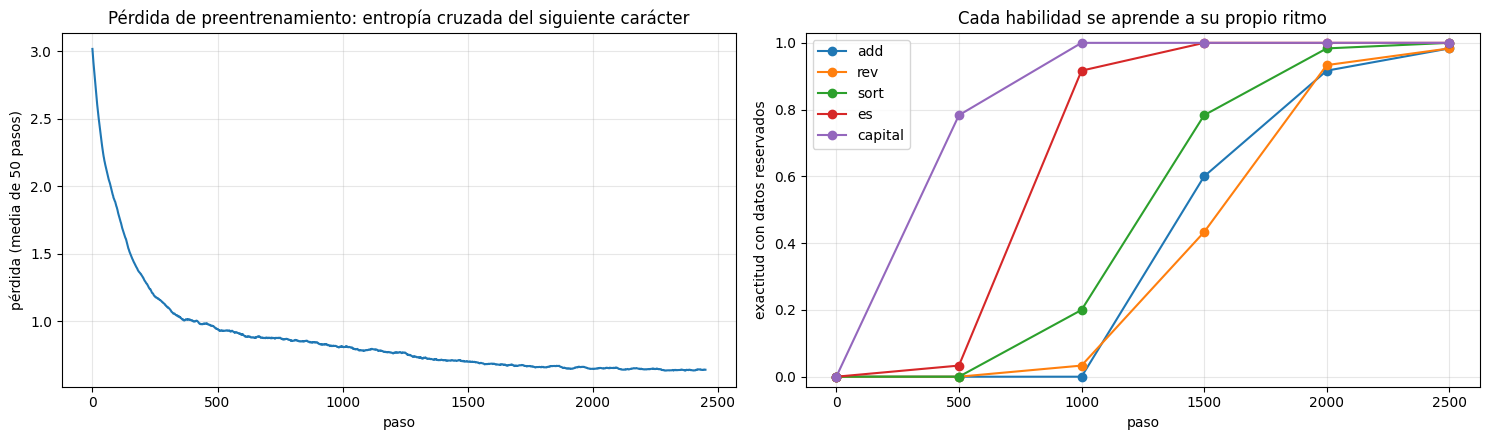

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
smooth = np.convolve(losses, np.ones(50) / 50, mode="valid")
axes[0].plot(smooth); axes[0].set_xlabel("paso"); axes[0].set_ylabel("pérdida (media de 50 pasos)")
axes[0].set_title("Pérdida de preentrenamiento: entropía cruzada del siguiente carácter"); axes[0].grid(alpha=0.3)
steps_eval = list(skill_curve)
for t in TASKS:
    axes[1].plot(steps_eval, [skill_curve[s][t] for s in steps_eval], marker="o", label=t)
axes[1].set_xlabel("paso"); axes[1].set_ylabel("exactitud con datos reservados"); axes[1].set_ylim(-0.03, 1.03)
axes[1].set_title("Cada habilidad se aprende a su propio ritmo"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Usar el generalista

El modelo no tiene cabezas ni caminos de código específicos de cada tarea. **Solo el prefijo de la instrucción** decide lo que hace. Todas las instrucciones de abajo están **reservadas**: esas sumas y frases nunca aparecieron en el entrenamiento, y las cadenas para invertir son letras aleatorias nuevas.

In [10]:
model.eval()
random.seed(42)
for t in TASKS:
    print(f"--- {t} ---")
    for _ in range(3):
        p, a = example(t, "test")
        out = complete(model, p)
        print(f"  {p}{out:28s} {'✓' if out == a else '✗ esperado ' + a}")

--- add ---
  add 71+42=113                          ✓
  add 39+14=53                           ✓
  add 4+41=45                           ✓
--- rev ---
  rev hhexd=dxehh                        ✓
  rev snb=bns                          ✓
  rev cgh=hgc                          ✓
--- sort ---
  sort 8 3 8=3 8 8                        ✓
  sort 3 7 9 4 0 2=0 2 3 4 7 9                  ✓
  sort 5 4 2 3 5 1=1 2 3 4 5 5                  ✓
--- es ---


  es she has the apple=ella tiene la manzana        ✓
  es we buy the new table=nosotros compramos la mesa nueva ✓


  es we want the red car=nosotros queremos el coche rojo ✓
--- capital ---
  capital norway=oslo                         ✓
  capital costa rica=san jose                     ✓
  capital norway=oslo                         ✓


### Alucinación: respuestas seguras a preguntas que no puede saber

El modelo aprendió el *formato* de una respuesta sobre capitales, no una forma de decir "no lo sé". Pregúntale por países que nunca vio (o que no existen) y aun así produce una ciudad de aspecto plausible, normalmente una mezcla de las que memorizó. Los grandes modelos de lenguaje alucinan por la misma razón: se entrenan para producir texto probable, y plausible no es lo mismo que verdadero. El postentrenamiento (sección 12) y la consulta de fuentes reales lo reducen, pero no lo eliminan del todo.

In [11]:
for country in ["france", "peru", "japan", "atlantis", "narnia", "germanyland", "nepal", "spainia"]:
    print(f"capital {country:12s} -> {complete(model, f'capital {country}='):14s}"
          f"{'(memorizado)' if country in COUNTRIES else '(nunca visto: alucinado)'}")

capital france       -> paris         (memorizado)
capital peru         -> lima          (memorizado)
capital japan        -> tokyo         (memorizado)
capital atlantis     -> moscow        (nunca visto: alucinado)


capital narnia       -> buenos aires  (nunca visto: alucinado)
capital germanyland  -> helsinki      (nunca visto: alucinado)
capital nepal        -> stockholm     (nunca visto: alucinado)


capital spainia      -> madrid        (nunca visto: alucinado)


### Generalización más allá de la distribución de entrenamiento

Las instrucciones de prueba de arriba no se habían visto, pero estaban *dentro de la distribución*. ¿Qué pasa con entradas que no se parecen a nada del entrenamiento?

In [12]:
probes = [("add 123+4=", "127", "número de 3 cifras (el entrenamiento usó 0..99)"),
          ("rev abcdefghij=", "jihgfedcba", "palabra de 10 letras (el entrenamiento usó 3..6)"),
          ("sort 9 8 7 6 5 4 3 2 1=", "1 2 3 4 5 6 7 8 9", "9 dígitos (el entrenamiento usó 3..6)"),
          ("es the cat eats the red apple=", "?", "sustantivo como sujeto (en el entrenamiento los sujetos eran pronombres)")]
for p, a, why in probes:
    out = complete(model, p)
    print(f"{p:32s} -> {out:22s} esperado {a:20s} [{why}]")

add 123+4=                       -> 36                     esperado 127                  [número de 3 cifras (el entrenamiento usó 0..99)]
rev abcdefghij=                  -> hghcdcb                esperado jihgfedcba           [palabra de 10 letras (el entrenamiento usó 3..6)]
sort 9 8 7 6 5 4 3 2 1=          -> 1 2 3 4 6 7 9          esperado 1 2 3 4 5 6 7 8 9    [9 dígitos (el entrenamiento usó 3..6)]


es the cat eats the red apple=   -> él come la manzana roja esperado ?                    [sustantivo como sujeto (en el entrenamiento los sujetos eran pronombres)]


Los modelos pequeños extrapolan mal: aprenden los patrones que cubren sus datos. Buena parte de la razón por la que los LLM de frontera parecen generales es que sus datos de entrenamiento cubren una variedad enorme de patrones. La generalización robusta fuera de la distribución sigue siendo un problema de investigación abierto.

## 8. Estrategias de muestreo

El modelo produce una distribución de probabilidad sobre el siguiente token. Cómo elegimos a partir de ella cambia su comportamiento:

| Estrategia | Regla | Efecto |
|---|---|---|
| Voraz | tomar el argmax | determinista, la mejor para tareas con una única respuesta correcta |
| Temperatura $T$ | muestrear de softmax(logits / $T$) | $T<1$ más marcada y segura, $T>1$ más aleatoria y creativa |
| Top-k | quedarse solo con los $k$ tokens más probables | corta la larga cola de disparates |
| Top-p (núcleo) | quedarse con el conjunto más pequeño cuya probabilidad total sea ≥ $p$ | adapta el corte a lo seguro que esté el modelo |

Primero, mira la propia distribución para dos instrucciones: una en la que la respuesta es segura y otra en la que muchas continuaciones son válidas.

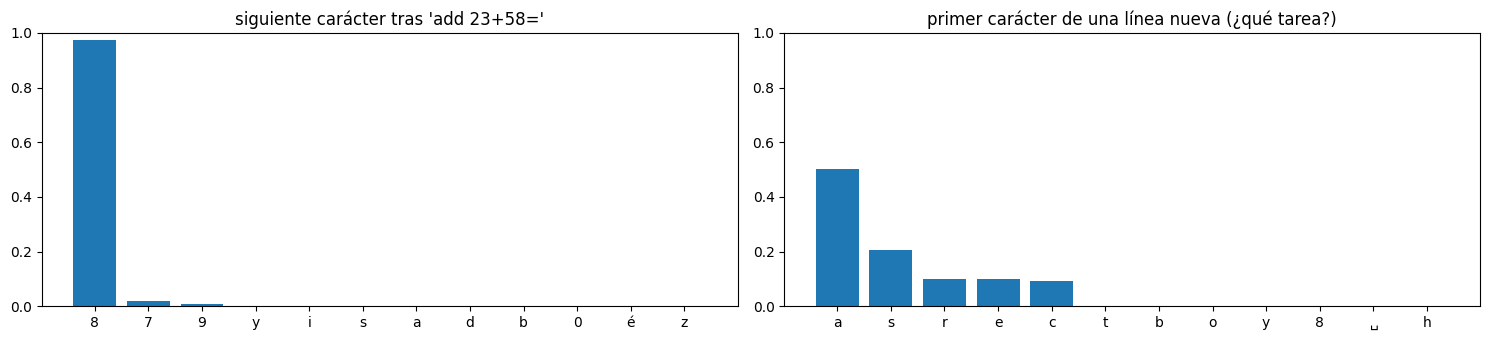

In [13]:
@torch.no_grad()
def next_char_probs(prompt):
    logits, _, _ = model(torch.tensor([encode("\n" + prompt)]))
    return logits[0, -1].softmax(-1)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
for ax, prompt in zip(axes, ["add 23+58=", "\n"]):
    p = next_char_probs(prompt if prompt != "\n" else "")
    top = p.topk(12)
    labels = [repr(itos[i])[1:-1] if itos[i] != " " else "␣" for i in top.indices.tolist()]
    ax.bar(labels, top.values.numpy(), color="tab:blue")
    ax.set_title(f"siguiente carácter tras {prompt!r}" if prompt != "\n" else "primer carácter de una línea nueva (¿qué tarea?)")
    ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

In [14]:
@torch.no_grad()
def generate(model, prompt="\n", max_new=200, temperature=1.0, top_k=None, top_p=None, seed=0):
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([encode(prompt)])
    for _ in range(max_new):
        logits, _, _ = model(idx[:, -BLOCK:])
        logits = logits[0, -1]
        if temperature == 0:
            nxt = logits.argmax().view(1)
        else:
            logits = logits / temperature
            if top_k is not None:
                kth = logits.topk(top_k).values[-1]
                logits = logits.masked_fill(logits < kth, float("-inf"))
            probs = logits.softmax(-1)
            if top_p is not None:
                sorted_p, order = probs.sort(descending=True)
                keep = sorted_p.cumsum(0) - sorted_p < top_p        # el conjunto más pequeño que alcanza top_p
                probs = torch.zeros_like(probs).scatter(0, order[keep], sorted_p[keep])
                probs = probs / probs.sum()
            nxt = torch.multinomial(probs, 1, generator=g)
        idx = torch.cat([idx, nxt.view(1, 1)], dim=1)
    return decode(idx[0].tolist())

for label, kw in [("voraz (T=0)", dict(temperature=0)),
                  ("T=0.5", dict(temperature=0.5)),
                  ("T=1.0, top-p 0.9", dict(temperature=1.0, top_p=0.9)),
                  ("T=2.0 (demasiado caliente)", dict(temperature=2.0))]:
    text = generate(model, "\n", max_new=150, **kw)
    print(f"===== {label} =====\n{text.strip()}\n")

===== voraz (T=0) =====
add 99+99=198
add 15+60=75
add 77+84=161
add 18+88=106
add 74+87=161
add 18+84=102
add 74+87=161
add 18+84=102
add 74+87=161
add 18+84=102
add 74+87=1



===== T=0.5 =====
add 87+74=161
add 29+27=56
add 60+6=66
add 55+52=107
add 68+88=156
add 6+59=65
add 41+39=70
rev xaz=zax
capital china=beijing
add 65+31=96
add 49+35=8



===== T=1.0, top-p 0.9 =====
sort 7 7 2 1 6 7=1 2 6 7 7 7
add 61+90=151
rev izktws=swtkzi
add 95+22=117
add 85+74=169
add 58+74=132
add 73+27=100
add 79+12=91
add 16+66=82
sort 7



===== T=2.0 (demasiado caliente) =====
scra
add 2chilzdn=29
add 38+17=64
re0 2 7=0 bjbiy
sos they wants thy the ixple=e5 denfo
es i see the shirtue3 2 2 2=u3 veo9
sort 9 5=5ú
capital brazil



Sin instrucción, el modelo "sueña" sus propios datos de entrenamiento: elige una tarea y escribe un ejemplo. La decodificación voraz se queda atascada repitiendo la línea más probable; una temperatura moderada da líneas variadas y en su mayoría válidas; una temperatura alta rompe el formato. Es el mismo mando que ajustas en la API de cualquier LLM.

## 9. Dentro del modelo: la atención mientras suma

Para escribir la respuesta a `add 47+38=`, el modelo debe encontrar los dígitos correctos de ambos números. Dibujamos la atención de cada cabeza desde las últimas posiciones (donde se producen los dígitos de la respuesta) hacia atrás sobre la instrucción.

add 47+38=85


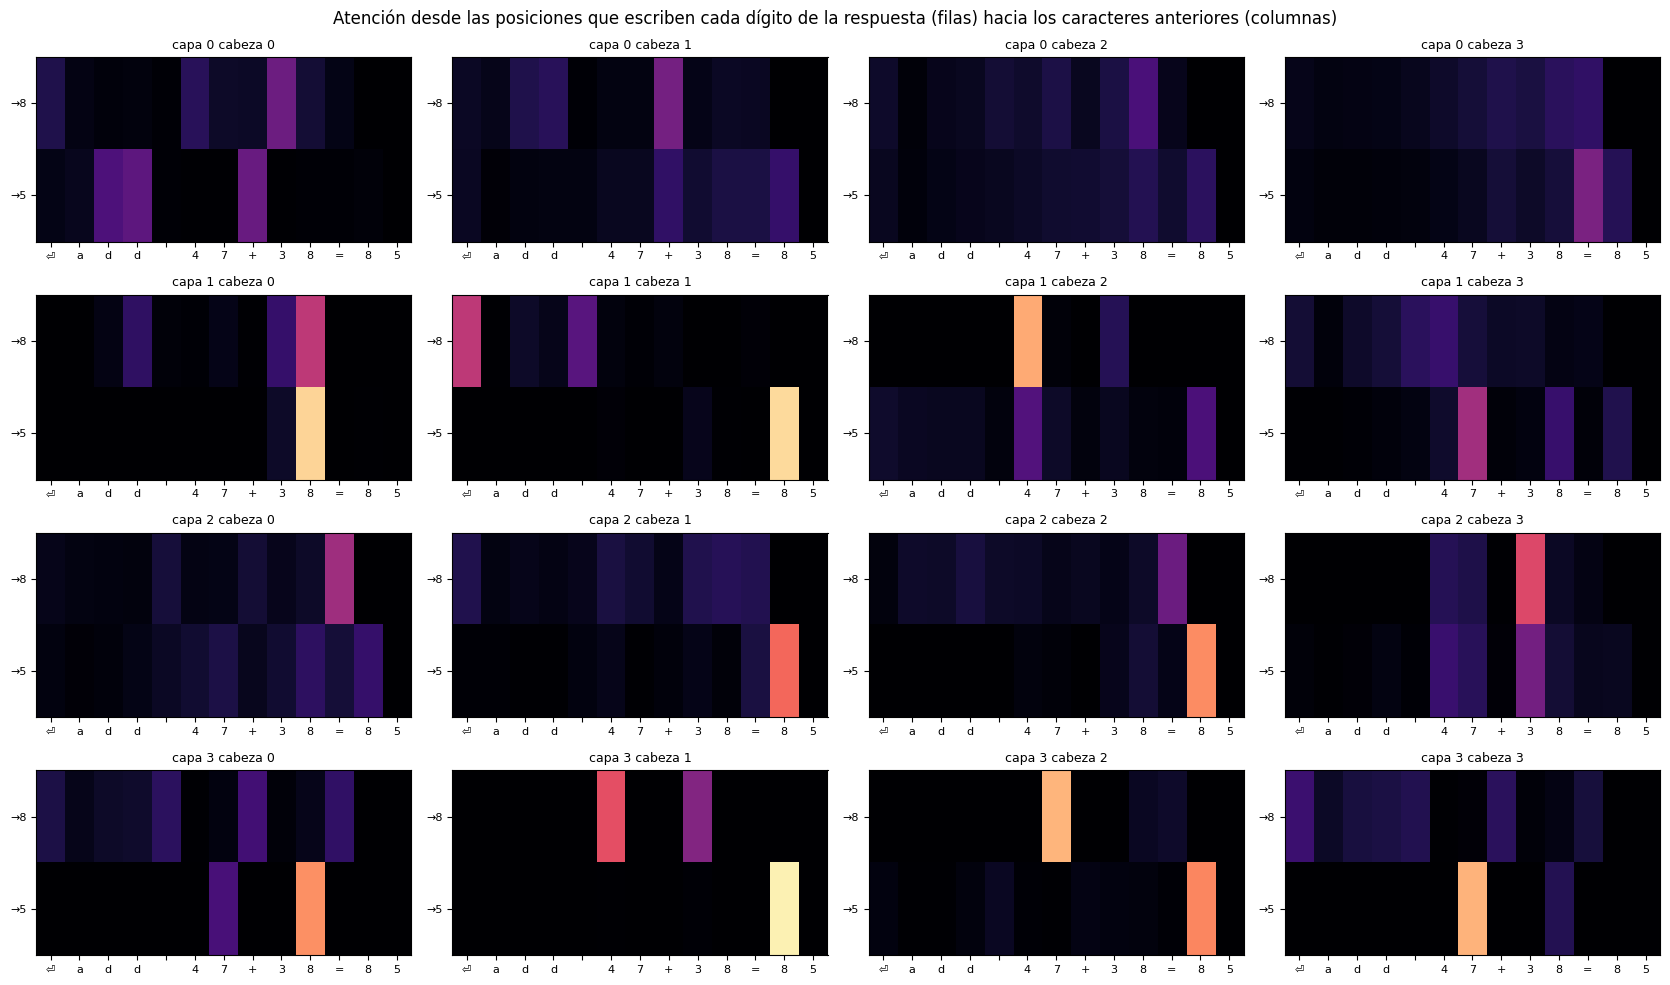

In [15]:
prompt = "add 47+38="
answer = complete(model, prompt)
full = "\n" + prompt + answer
idx = torch.tensor([encode(full)])
with torch.no_grad():
    model(idx, keep_attn=True)
labels = [c if c != "\n" else "⏎" for c in full]
q_rows = list(range(len(full) - len(answer) - 1, len(full) - 1))   # posiciones que predicen cada dígito de la respuesta
print(f"{prompt}{answer}")

L, H = len(model.blocks), model.blocks[0].attn.h
fig, axes = plt.subplots(L, H, figsize=(4.2 * H, 2.5 * L))
for l in range(L):
    for h in range(H):
        A = model.blocks[l].attn.last_attn[0, h][q_rows].numpy()
        ax = axes[l, h]
        ax.imshow(A, cmap="magma", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8)
        ax.set_yticks(range(len(q_rows))); ax.set_yticklabels([f"→{answer[i]}" for i in range(len(answer))], fontsize=8)
        ax.set_title(f"capa {l} cabeza {h}", fontsize=9)
fig.suptitle("Atención desde las posiciones que escriben cada dígito de la respuesta (filas) hacia los caracteres anteriores (columnas)")
plt.tight_layout(); plt.show()

Busca cabezas que pongan su peso en los dígitos de los dos operandos de la misma columna (decenas con decenas, unidades con unidades): esas cabezas reúnen las entradas que necesita un sumador, mientras que los MLP hacen la aritmética de los dígitos. Otras cabezas atienden a los signos `=` o `+`, que marcan *en qué punto* del problema está el modelo. La investigación en interpretabilidad de modelos grandes encuentra cabezas de "inducción" y de "copia" parecidas.

## 10. Generación rápida con una caché KV

Generar el token $t$ requiere atención sobre los $t-1$ tokens anteriores. Sin caché, cada paso vuelve a calcular las claves y los valores de todo el prefijo: $O(n^2)$ de trabajo para $n$ tokens. Como las claves y los valores anteriores nunca cambian (¡máscara causal!), podemos **guardarlos en caché** y calcular solo $q, k, v$ del token nuevo en cada paso. Todos los servidores de LLM en producción lo hacen; la memoria que ocupa la caché es una de las grandes razones de innovaciones como la atención de consultas agrupadas.

In [16]:
@torch.no_grad()
def generate_greedy_nocache(model, prompt, n):
    idx = torch.tensor([encode(prompt)])
    for _ in range(n):
        logits, _, _ = model(idx)                       # se recalcula todo en cada paso
        idx = torch.cat([idx, logits[:, -1].argmax(-1, keepdim=True)], dim=1)
    return decode(idx[0].tolist())

@torch.no_grad()
def generate_greedy_cache(model, prompt, n):
    idx = torch.tensor([encode(prompt)])
    logits, _, past = model(idx)                        # se procesa la instrucción una sola vez
    out = idx
    for _ in range(n):
        nxt = logits[:, -1].argmax(-1, keepdim=True)
        out = torch.cat([out, nxt], dim=1)
        logits, _, past = model(nxt, past=past)         # solo el token nuevo pasa por el modelo
    return decode(out[0].tolist())

prompt, n_new = "\nadd 12+30=42\nrev hello=olleh\n", BLOCK - 32
t0 = time.time(); a = generate_greedy_nocache(model, prompt, n_new); t_no = time.time() - t0
t0 = time.time(); b = generate_greedy_cache(model, prompt, n_new); t_kv = time.time() - t0
print("salida idéntica:", a == b)
print(f"sin caché {t_no * 1000:.0f} ms, con caché KV {t_kv * 1000:.0f} ms ({t_no / t_kv:.1f} veces más rápido)")
with torch.no_grad():
    _, _, past = model(torch.tensor([encode(prompt)]))
print(f"caché: {len(past)} capas x (claves, valores), cada una con forma {tuple(past[0][0].shape)} = (lote, cabezas, tokens hasta ahora, dim. de cabeza)")

salida idéntica: True
sin caché 126 ms, con caché KV 76 ms (1.7 veces más rápido)
caché: 4 capas x (claves, valores), cada una con forma (1, 4, 30, 32) = (lote, cabezas, tokens hasta ahora, dim. de cabeza)


La aceleración crece con la longitud de la secuencia; con miles de tokens es enorme.

## 11. Ajuste fino: por qué importa el preentrenamiento

La receta de GPT-1, que se sigue usando hoy: **preentrenar** una vez con muchos datos generales y después hacer un **ajuste fino** breve con un pequeño conjunto de datos específico de la tarea.

Una tarea nueva que el modelo nunca ha visto: traducir **de español a inglés** (`en ella quiere el coche rojo=she wants the red car`). Damos a dos modelos idénticos los mismos 200 pasos de ajuste fino:
* uno parte de nuestros pesos preentrenados (ya conoce ambos vocabularios y cómo se corresponden),
* otro parte de pesos aleatorios.

ambos ajustados en 123 s
exactitud ES→EN con datos reservados:  desde el preentrenado 100%   desde cero 0%


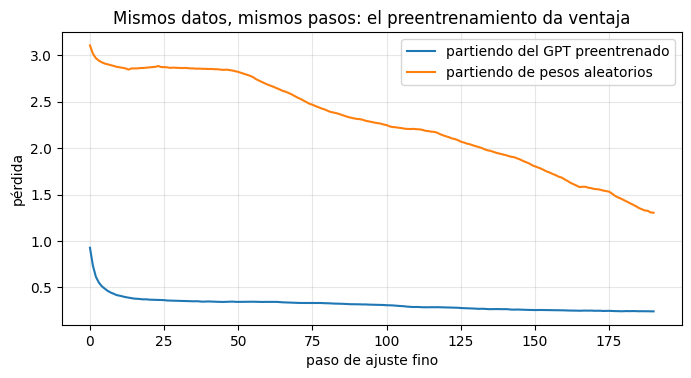

  en él come la casa=he eats the house        esperado: he eats the house
  en él ve el perro nuevo=he sees the new dog      esperado: he sees the new dog
  en él compra el libro viejo=he buys the old book     esperado: he buys the old book


  en ella tiene la casa=she has the house        esperado: she has the house


In [17]:
def new_task_example(split):
    en, es = random.choice(TR_TRAIN if split == "train" else TR_TEST)
    return f"en {es}=", en

random.seed(7)
ft_corpus = "\n".join("".join(new_task_example("train")) for _ in range(5000)) + "\n"
ft_data = torch.tensor(encode(ft_corpus), dtype=torch.long)
pretrained_state = {k: v.clone() for k, v in model.state_dict().items()}

def finetune(start_from_pretrained, steps=200):
    torch.manual_seed(0)
    m = GPT(len(chars), BLOCK, d=128, n_layer=4, n_head=4)
    if start_from_pretrained:
        m.load_state_dict(pretrained_state)
    o = torch.optim.AdamW(m.parameters(), lr=5e-4 if start_from_pretrained else 2e-3)
    curve = []
    for s in range(steps):
        xb, yb = get_batch(32, ft_data)
        _, loss, _ = m(xb, yb)
        o.zero_grad(); loss.backward(); o.step()
        curve.append(loss.item())
    m.eval()
    random.seed(99)
    acc = np.mean([complete(m, p) == a for p, a in (new_task_example("test") for _ in range(100))])
    return m, curve, acc

t0 = time.time()
ft_model, curve_pre, acc_pre = finetune(True)
_, curve_scratch, acc_scratch = finetune(False)
print(f"ambos ajustados en {time.time() - t0:.0f} s")
print(f"exactitud ES→EN con datos reservados:  desde el preentrenado {acc_pre:.0%}   desde cero {acc_scratch:.0%}")

plt.figure(figsize=(8, 3.8))
plt.plot(np.convolve(curve_pre, np.ones(10) / 10, "valid"), label="partiendo del GPT preentrenado")
plt.plot(np.convolve(curve_scratch, np.ones(10) / 10, "valid"), label="partiendo de pesos aleatorios")
plt.xlabel("paso de ajuste fino"); plt.ylabel("pérdida"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Mismos datos, mismos pasos: el preentrenamiento da ventaja"); plt.show()

random.seed(5)
for _ in range(4):
    p, a = new_task_example("test")
    print(f"  {p}{complete(ft_model, p):24s} esperado: {a}")

### Olvido catastrófico

Ajustar solo con la tarea nueva puede dañar las habilidades antiguas, porque nada en la pérdida las protege. El ajuste fino real mezcla algunos datos generales o usa métodos eficientes en parámetros como **LoRA**, que congelan los pesos originales y entrenan pequeñas matrices añadidas.

In [18]:
after = evaluate(ft_model)
print(f"{'tarea':8s} {'antes del ajuste':>17s} {'después':>8s}")
for t in TASKS:
    print(f"{t:8s} {skill_curve[STEPS][t]:17.0%} {after[t]:8.0%}")

tarea     antes del ajuste  después
add                    98%      12%
rev                    98%       0%
sort                  100%      17%
es                    100%       0%
capital               100%       0%


## 12. De un modelo base a ChatGPT, y las leyes de escala

Lo que entrenamos es un **modelo base**: continúa el texto al estilo de sus datos de entrenamiento. Convertir un modelo base en un asistente requiere etapas adicionales:

```mermaid
flowchart LR
    A[Preentrenamiento<br/>predecir el siguiente token<br/>billones de tokens] --> B[Ajuste fino supervisado SFT<br/>instrucción escrita por humanos → respuesta ideal]
    B --> C[Ajuste por preferencias<br/>RLHF con un modelo de recompensa, o DPO<br/>humanos ordenan respuestas]
    C --> D[Asistente<br/>+ herramientas, búsqueda, sistemas de seguridad]
```

| Etapa | Datos | Qué enseña |
|---|---|---|
| Preentrenamiento | web, libros, código (la mayor parte del cálculo) | conocimiento, lenguaje, habilidades |
| Ajuste fino supervisado (SFT) | decenas de miles de conversaciones seleccionadas | el *formato* de un asistente: responder a la pregunta, seguir instrucciones |
| RLHF / DPO | preferencias humanas (o de una IA) entre respuestas | ser útil, honesto e inofensivo; negarse cuando corresponde; decir "no lo sé" |
| Uso de herramientas y búsqueda | demostraciones de llamadas a herramientas | consultar datos en lugar de alucinar (sección 7), ejecutar código, navegar |

Fíjate en que nuestro modelo ya hace una versión diminuta de SFT: el formato `tarea entrada=respuesta` es un formato de instrucción. El prefijo de la instrucción *es* la instrucción.

### Aprendizaje en contexto

Los GPT grandes pueden aprender una tarea nueva a partir de unos pocos ejemplos colocados **en la instrucción**, sin ninguna actualización de pesos (el hallazgo principal de GPT-3). Nuestro modelo es demasiado pequeño para eso: solo puede hacer tareas cuyo formato vio durante el entrenamiento. El aprendizaje en contexto es una de las capacidades que aparecen con la escala.

### Leyes de escala

Kaplan et al. (2020) y Hoffmann et al. (2022, "Chinchilla") encontraron que la pérdida baja siguiendo una **ley de potencias** suave en los parámetros $N$, los datos $D$ y el cálculo $C$. Dos reglas prácticas:
* Cálculo de entrenamiento ≈ $6ND$ operaciones de coma flotante.
* El entrenamiento óptimo en cálculo usa unos **20 tokens por parámetro**.

In [19]:
tokens_seen = STEPS * BATCH * BLOCK
ours = 6 * n_params * tokens_seen
rows = [("this notebook", n_params, tokens_seen),
        ("GPT-2 XL", 1.5e9, 1e10),
        ("GPT-3", 175e9, 300e9),
        ("Chinchilla", 70e9, 1.4e12)]
print(f"{'modelo':14s} {'parámetros':>10s} {'tokens':>10s} {'tokens/parám.':>13s} {'FLOPs entren. (6ND)':>20s} {'× el nuestro':>13s}")
for name, N, D in rows:
    print(f"{name:14s} {N:10.2e} {D:10.2e} {D / N:13.1f} {6 * N * D:20.2e} {6 * N * D / ours:13.1e}")

modelo         parámetros     tokens tokens/parám.  FLOPs entren. (6ND)  × el nuestro
this notebook    8.07e+05   5.12e+06           6.3             2.48e+13       1.0e+00
GPT-2 XL         1.50e+09   1.00e+10           6.7             9.00e+19       3.6e+06
GPT-3            1.75e+11   3.00e+11           1.7             3.15e+23       1.3e+10
Chinchilla       7.00e+10   1.40e+12          20.0             5.88e+23       2.4e+10


El entrenamiento de GPT-3 usó aproximadamente **diez mil millones de veces** el cálculo de la ejecución que acabas de hacer, con esencialmente la misma arquitectura y el mismo objetivo.

## Ideas clave

* Un GPT es una pila de bloques transformer **causales** (atención + MLP) entrenada para **predecir el siguiente token**.
* El texto se convierte en enteros con un tokenizador; BPE equilibra el tamaño del vocabulario con la longitud de la secuencia.
* Predecir el siguiente token con texto variado obliga al modelo a aprender muchas habilidades; la **instrucción** elige cuál usar. Por eso un solo modelo puede ser generalista.
* Las habilidades surgen en momentos distintos del entrenamiento; la pérdida es suave, las capacidades pueden ser abruptas.
* El modelo aprende la *forma* de las respuestas, así que puede **alucinar**; además extrapola mal fuera de su distribución de entrenamiento.
* El muestreo (temperatura, top-k, top-p) intercambia fiabilidad por diversidad; la **caché KV** hace rápida la generación.
* **Preentrenar y después ajustar** transfiere conocimiento; un ajuste fino ingenuo provoca **olvido**.
* Los asistentes como ChatGPT añaden SFT y ajuste por preferencias sobre un modelo base, y la diferencia restante es sobre todo de **escala**.

## Ejercicios

1. Quita `capital` del corpus y vuelve a entrenar. ¿Cambia la capacidad del modelo en las demás tareas?
2. Entrena con `WEIGHTS = [1, 1, 1, 1, 1]`. ¿Cómo cambia la curva de la suma en la sección 6?
3. Escribe la respuesta de la suma **al revés** (`add 47+38=58`, las unidades primero). ¿Por qué podría facilitar la aritmética a un modelo que escribe de izquierda a derecha?
4. Sustituye los tokens de caracteres por el tokenizador BPE de la sección 2 entrenado con el corpus. ¿Qué les pasa a la longitud de las secuencias y a la velocidad de entrenamiento?
5. Añade al corpus una tarea nueva, `max 3 9 2=9`, y vuelve a entrenar. Después, sin volver a entrenar, prueba a dar unos pocos ejemplos en la instrucción con un formato de tarea no visto. ¿Funciona?
6. Duplica `d` (la anchura del modelo) o `n_layer`, manteniendo fijo el número de pasos. Dibuja la pérdida final frente al número de parámetros: ¿se ve el inicio de una ley de escala?